# KneeGait-Edge: Random Forest Gait Pattern Classification

**KneeGait-Edge** is a low-cost edge wearable biomechanical monitoring system designed to detect dynamic gait impairment associated with Knee Osteoarthritis (KOA). Utilizing dual 6-DOF inertial measurement units (MPU-6050) placed on the lateral thigh and anteromedial shank, the device captures continuous 50Hz sagittal knee flexion-extension kinematics.

### Objective
This notebook demonstrates an end-to-end machine learning pipeline:
1. Loading the 20,000-stride synthetic training dataset (`data.csv`).
2. Performing exploratory data analysis, validation, and feature distribution inspections.
3. Training a `RandomForestClassifier` on 4 biomechanical features derived from the KneeGait-Edge Master Engineering Blueprint:
   - `peak_swing_flexion` (deg)
   - `flexion_rom` (deg)
   - `stance_to_swing_ratio` (dimensionless)
   - `mean_angular_velocity` (deg/s)
4. Evaluating classification performance using stratified 80/20 test split.
5. Analyzing feature importances and exporting the trained model and metadata for TinyML deployment.

> **Research & Diagnostic Disclaimer:** The dataset used in this study is synthetic, generated from class-conditioned multivariate distributions under physical constraints. These results demonstrate edge-AI feasibility and do not constitute clinically validated diagnostic efficacy in real-world patients.

## 2. Imports and Configuration

We load essential scientific computing, visualization, and machine learning libraries, configure consistent plotting aesthetics, and set a global random seed (`42`) for 100% reproducibility.

In [1]:
import os
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score
)

# Visual styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
sns.set_palette('deep')
plt.rcParams['font.size'] = 10
plt.rcParams['figure.titlesize'] = 12

# Configuration parameters
RANDOM_SEED = 42
TARGET_COLUMN = 'target'
FEATURE_NAMES = [
    'peak_swing_flexion',
    'flexion_rom',
    'stance_to_swing_ratio',
    'mean_angular_velocity'
]
CLASS_NAMES = ['HIGH_KOA_RISK', 'NORMAL_GAIT']
DATA_PATH = 'data.csv'

print(f"Configuration loaded. Target: '{TARGET_COLUMN}', Features: {FEATURE_NAMES}")

Configuration loaded. Target: 'target', Features: ['peak_swing_flexion', 'flexion_rom', 'stance_to_swing_ratio', 'mean_angular_velocity']


## 3. Load the Dataset

We read the primary dataset (`data.csv`) into a pandas DataFrame and examine its shape, column headers, and initial rows.

In [2]:
df = pd.read_csv(DATA_PATH)

print(f"Dataset Shape: {df.shape[0]:,} rows x {df.shape[1]} columns")
print(f"Column Names:  {df.columns.tolist()}\n")
print("Data Types:")
print(df.dtypes)
print("\nFirst 5 Stride Records:")
df.head()

Dataset Shape: 20,000 rows x 5 columns
Column Names:  ['peak_swing_flexion', 'flexion_rom', 'stance_to_swing_ratio', 'mean_angular_velocity', 'target']

Data Types:
peak_swing_flexion       float64
flexion_rom              float64
stance_to_swing_ratio    float64
mean_angular_velocity    float64
target                    object
dtype: object

First 5 Stride Records:


,peak_swing_flexion,flexion_rom,stance_to_swing_ratio,mean_angular_velocity,target
0,30.300489,28.363398,2.057734,66.754021,HIGH_KOA_RISK
1,66.196162,63.702954,1.222198,130.972246,NORMAL_GAIT
2,34.828340,30.628723,1.770736,74.306215,HIGH_KOA_RISK
3,58.444722,56.865252,1.530585,128.217393,NORMAL_GAIT
4,41.795674,36.622841,1.688211,73.611582,HIGH_KOA_RISK


## 4. Initial Data Inspection

Before statistical modeling, we verify dataset integrity: checking for null values, infinite values, duplicate records, and the observed class balance.

--- Data Integrity Audit ---
Missing Values:    0
Infinite Values:   0
Duplicate Rows:    0

--- Class Balance ---
               Count  Percentage (%)
target                              
HIGH_KOA_RISK  14819          74.095
NORMAL_GAIT     5181          25.905


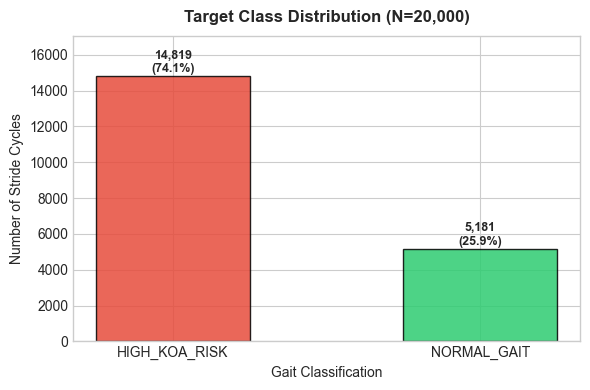

In [3]:
# Data integrity checks
n_nulls = df.isnull().sum().sum()
n_infs = (~np.isfinite(df[FEATURE_NAMES].values)).sum()
n_dups = df.duplicated().sum()

print("--- Data Integrity Audit ---")
print(f"Missing Values:    {n_nulls}")
print(f"Infinite Values:   {n_infs}")
print(f"Duplicate Rows:    {n_dups}")

# Target class counts and proportions
counts = df[TARGET_COLUMN].value_counts()
props = df[TARGET_COLUMN].value_counts(normalize=True) * 100

summary_target = pd.DataFrame({'Count': counts, 'Percentage (%)': props.round(3)})
print("\n--- Class Balance ---")
print(summary_target)

# Visualize class distribution
plt.figure(figsize=(6, 4))
colors = ['#e74c3c' if c == 'HIGH_KOA_RISK' else '#2ecc71' for c in summary_target.index]
bars = plt.bar(summary_target.index, summary_target['Count'], color=colors, edgecolor='black', alpha=0.85, width=0.5)
plt.title("Target Class Distribution (N=20,000)", fontweight='bold', pad=10)
plt.xlabel("Gait Classification")
plt.ylabel("Number of Stride Cycles")
for bar, cnt, pct in zip(bars, summary_target['Count'], summary_target['Percentage (%)']):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 200, f"{cnt:,}\n({pct:.1f}%)", ha='center', fontsize=9, fontweight='bold')
plt.ylim(0, max(summary_target['Count']) * 1.15)
plt.tight_layout()
plt.show()

## 5. Feature Distributions by Class

We plot kernel density estimates (KDE) and histograms for all four input features, grouped by target class (`NORMAL_GAIT` vs `HIGH_KOA_RISK`). This highlights the distinct physiological profiles and the realistic transitional overlap between groups.

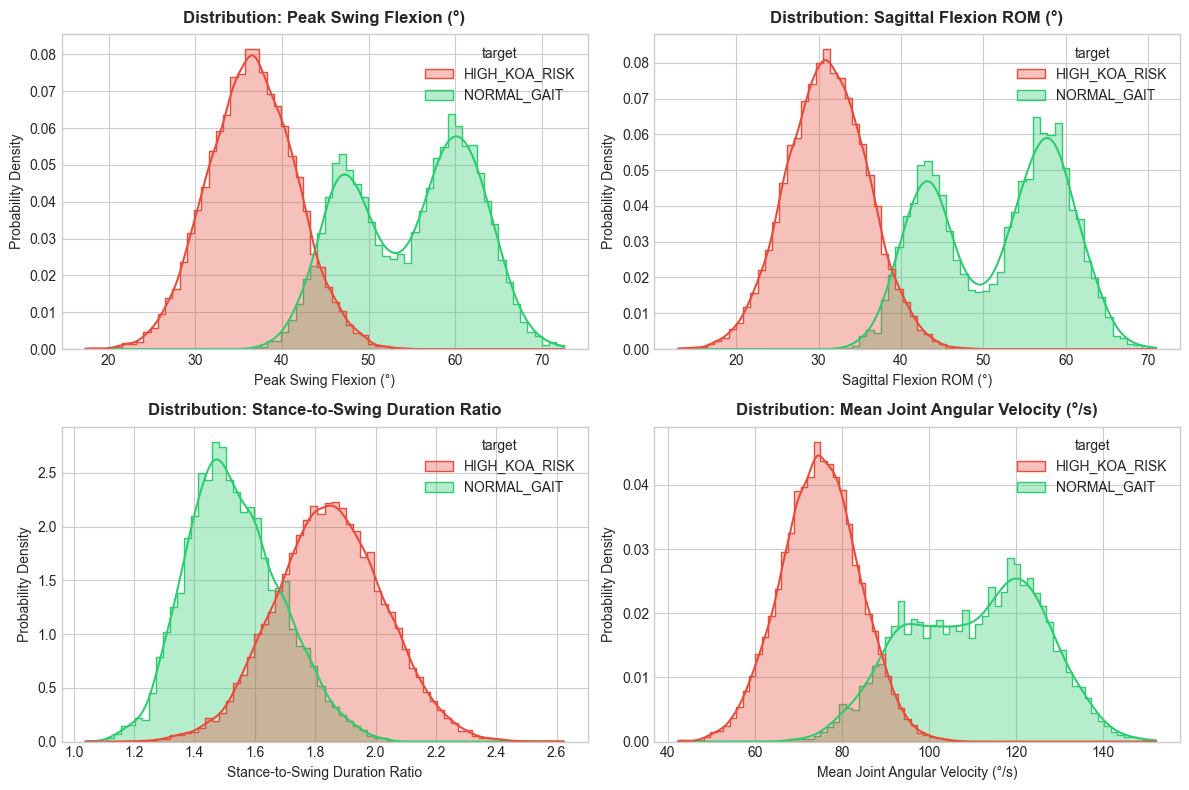

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.flatten()

feature_titles = {
    'peak_swing_flexion': 'Peak Swing Flexion (°)',
    'flexion_rom': 'Sagittal Flexion ROM (°)',
    'stance_to_swing_ratio': 'Stance-to-Swing Duration Ratio',
    'mean_angular_velocity': 'Mean Joint Angular Velocity (°/s)'
}

palette = {'NORMAL_GAIT': '#2ecc71', 'HIGH_KOA_RISK': '#e74c3c'}

for i, col in enumerate(FEATURE_NAMES):
    ax = axes[i]
    sns.histplot(
        data=df,
        x=col,
        hue=TARGET_COLUMN,
        palette=palette,
        kde=True,
        element='step',
        stat='density',
        common_norm=False,
        alpha=0.35,
        ax=ax
    )
    ax.set_title(f"Distribution: {feature_titles[col]}", fontweight='bold', pad=8)
    ax.set_xlabel(feature_titles[col])
    ax.set_ylabel("Probability Density")

plt.tight_layout()
plt.show()

## 6. Correlation Analysis

We calculate Pearson correlation coefficients among the numeric input features. 
- Peak swing flexion and flexion ROM demonstrate strong positive correlation ($r \\approx 0.99$), reflecting natural joint kinematics.
- Stance-to-swing ratio exhibits strong negative correlation with angular velocity and flexion angles, as pathological stiff gait prolongs stance loading while restricting swing velocity.

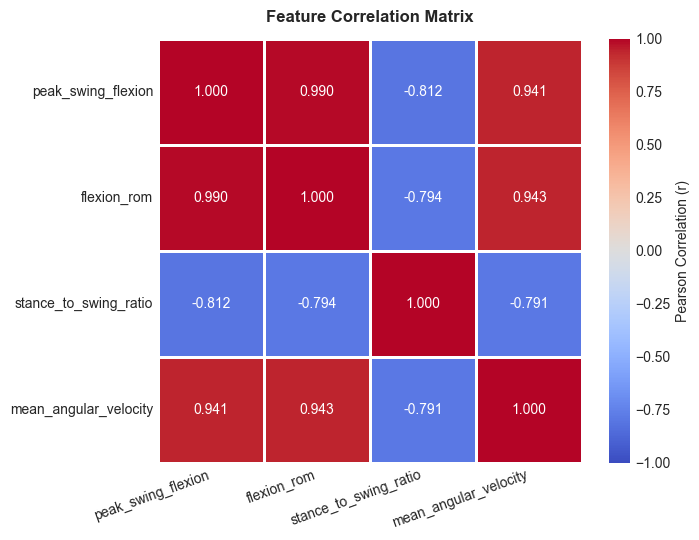

Numerical Correlation Matrix:


,peak_swing_flexion,flexion_rom,stance_to_swing_ratio,mean_angular_velocity
peak_swing_flexion,1.0000,0.9895,-0.8118,0.9407
flexion_rom,0.9895,1.0000,-0.7944,0.9430
stance_to_swing_ratio,-0.8118,-0.7944,1.0000,-0.7912
mean_angular_velocity,0.9407,0.9430,-0.7912,1.0000


In [5]:
corr_matrix = df[FEATURE_NAMES].corr()

plt.figure(figsize=(7, 5.5))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool), k=1)
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".3f",
    cmap='coolwarm',
    vmin=-1.0,
    vmax=1.0,
    square=True,
    linewidths=1.0,
    cbar_kws={'label': 'Pearson Correlation (r)'}
)
plt.title("Feature Correlation Matrix", fontweight='bold', pad=12)
plt.xticks(rotation=20, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

print("Numerical Correlation Matrix:")
corr_matrix.round(4)

## 7. Define Feature Matrix (X) and Target Vector (y)

We isolate the four blueprint-specified input features into matrix `X` and the classification label into vector `y`. We verify that the target column is strictly excluded from `X` to avoid data leakage.

In [6]:
X = df[FEATURE_NAMES].copy()
y = df[TARGET_COLUMN].copy()

print(f"Feature matrix X shape: {X.shape} (Features: {X.columns.tolist()})")
print(f"Target vector y shape:  {y.shape} (Unique classes: {np.unique(y).tolist()})")

assert TARGET_COLUMN not in X.columns, "Data leakage error: Target column found inside X!"
print("Verification passed: Target column strictly isolated from input features.")

Feature matrix X shape: (20000, 4) (Features: ['peak_swing_flexion', 'flexion_rom', 'stance_to_swing_ratio', 'mean_angular_velocity'])
Target vector y shape:  (20000,) (Unique classes: ['HIGH_KOA_RISK', 'NORMAL_GAIT'])
Verification passed: Target column strictly isolated from input features.


## 8. Stratified Train/Test Split

We partition the dataset into 80% training data (16,000 strides) and 20% held-out test data (4,000 strides). A stratified split ensures the identical class ratio is preserved across both partitions.

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_SEED,
    stratify=y
)

print(f"Training split: {len(X_train):,} strides ({len(X_train)/len(df)*100:.1f}%)")
print(f"Testing split:  {len(X_test):,} strides ({len(X_test)/len(df)*100:.1f}%)\n")

split_props = pd.DataFrame({
    'Train Count': y_train.value_counts(),
    'Train Pct (%)': (y_train.value_counts(normalize=True)*100).round(2),
    'Test Count': y_test.value_counts(),
    'Test Pct (%)': (y_test.value_counts(normalize=True)*100).round(2)
})
print("Stratification Verification Across Splits:")
split_props

Training split: 16,000 strides (80.0%)
Testing split:  4,000 strides (20.0%)

Stratification Verification Across Splits:


,Train Count,Train Pct (%),Test Count,Test Pct (%)
target,,,,
HIGH_KOA_RISK,11855,74.09,2964,74.1
NORMAL_GAIT,4145,25.91,1036,25.9


## 9. Train the Random Forest Classifier

We instantiate a `RandomForestClassifier` with:
- `n_estimators=200`: An ensemble of 200 decision trees to balance variance reduction and inference latency.
- `max_depth=8`: Constrained tree depth to prevent overfitting on boundary noise.
- `min_samples_split=5` and `min_samples_leaf=2`: Regularization to encourage robust decision boundaries.
- `random_state=42`: Ensuring full reproducibility.

The model is fitted exclusively on `X_train` and `y_train`.

In [8]:
clf = RandomForestClassifier(
    n_estimators=200,
    max_depth=8,
    min_samples_split=5,
    min_samples_leaf=2,
    random_state=RANDOM_SEED,
    n_jobs=-1
)

clf.fit(X_train, y_train)
print(f"Model successfully fitted with {len(clf.estimators_)} trees.")

Model successfully fitted with 200 trees.


## 10. Make Test Predictions

We evaluate the trained model on the untouched 4,000-stride test set and inspect a sample table comparing actual ground truth against model predictions and predicted probabilities.

In [9]:
y_pred = clf.predict(X_test)
y_proba = clf.predict_proba(X_test)

# Build sample comparison table
sample_df = X_test.head(10).copy()
sample_df['Actual'] = y_test.head(10).values
sample_df['Predicted'] = y_pred[:10]
sample_df['Confidence'] = [f"{prob.max()*100:.1f}%" for prob in y_proba[:10]]
sample_df['Match'] = sample_df['Actual'] == sample_df['Predicted']

print("Sample Predictions vs Ground Truth (First 10 Test Strides):")
sample_df

Sample Predictions vs Ground Truth (First 10 Test Strides):


,peak_swing_flexion,flexion_rom,stance_to_swing_ratio,mean_angular_velocity,Actual,Predicted,Confidence,Match
15041,29.634143,23.078991,2.007681,70.679649,HIGH_KOA_RISK,HIGH_KOA_RISK,100.0%,True
13017,45.685855,40.066354,1.732069,88.008625,HIGH_KOA_RISK,HIGH_KOA_RISK,64.8%,True
9360,29.354836,23.041637,2.065151,69.646493,HIGH_KOA_RISK,HIGH_KOA_RISK,100.0%,True
11434,63.297833,60.329618,1.399833,119.904853,NORMAL_GAIT,NORMAL_GAIT,100.0%,True
6371,42.003300,36.718742,1.490457,94.541325,HIGH_KOA_RISK,HIGH_KOA_RISK,98.6%,True
16208,33.365568,27.273606,2.012660,69.895705,HIGH_KOA_RISK,HIGH_KOA_RISK,100.0%,True
10860,44.806467,39.200538,1.713153,86.569379,HIGH_KOA_RISK,HIGH_KOA_RISK,74.7%,True
9288,27.942458,23.448025,2.009769,71.249591,HIGH_KOA_RISK,HIGH_KOA_RISK,100.0%,True
14272,36.970841,29.954051,1.810422,65.356007,HIGH_KOA_RISK,HIGH_KOA_RISK,100.0%,True
17397,60.739113,58.655490,1.472611,109.960448,NORMAL_GAIT,NORMAL_GAIT,100.0%,True


## 11. Comprehensive Performance Evaluation

We compute primary statistical metrics on the held-out test set:
- **Accuracy**: Overall proportion of correctly identified strides.
- **Balanced Accuracy**: Macro-average of recall across both classes, accounting for class imbalance.
- **Precision, Recall, and F1-Score**: Detailed diagnostic performance metrics per class.

In [10]:
acc = accuracy_score(y_test, y_pred)
bal_acc = balanced_accuracy_score(y_test, y_pred)
macro_p = precision_score(y_test, y_pred, average='macro')
macro_r = recall_score(y_test, y_pred, average='macro')
macro_f1 = f1_score(y_test, y_pred, average='macro')
weighted_f1 = f1_score(y_test, y_pred, average='weighted')

print("=" * 55)
print("     KNEEGAT-EDGE TEST SET EVALUATION METRICS")
print("=" * 55)
print(f"Accuracy:           {acc:.4f} ({acc*100:.2f}%)")
print(f"Balanced Accuracy:  {bal_acc:.4f} ({bal_acc*100:.2f}%)")
print(f"Macro Precision:    {macro_p:.4f}")
print(f"Macro Recall:       {macro_r:.4f}")
print(f"Macro F1-Score:     {macro_f1:.4f}")
print(f"Weighted F1-Score:  {weighted_f1:.4f}")
print("=" * 55)
print("\nDetailed Classification Report:")
print(classification_report(y_test, y_pred, labels=CLASS_NAMES, digits=4))

     KNEEGAT-EDGE TEST SET EVALUATION METRICS
Accuracy:           0.9728 (97.28%)
Balanced Accuracy:  0.9643 (96.43%)
Macro Precision:    0.9646
Macro Recall:       0.9643
Macro F1-Score:     0.9645
Weighted F1-Score:  0.9727

Detailed Classification Report:


               precision    recall  f1-score   support

HIGH_KOA_RISK     0.9815    0.9818    0.9816      2964
  NORMAL_GAIT     0.9478    0.9469    0.9474      1036

     accuracy                         0.9728      4000
    macro avg     0.9646    0.9643    0.9645      4000
 weighted avg     0.9727    0.9728    0.9727      4000



## 12. Confusion Matrix

The confusion matrix visually displays true positives, true negatives, false positives, and false negatives:
- **Diagonal Elements**: Correct classifications (True High KOA Risk and True Normal Gait).
- **Off-Diagonal Elements**: Misclassifications resulting from physiological overlap in borderline strides.

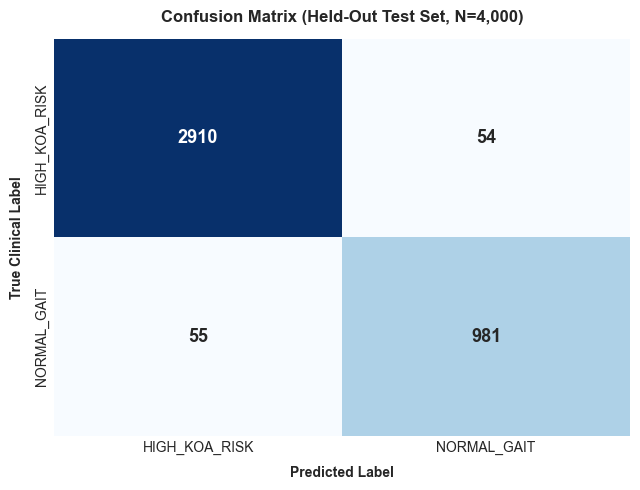

True High KOA Risk (TP):  2,910
False Normal Gait (FN):   54
False High KOA Risk (FP): 55
True Normal Gait (TN):    981


In [11]:
cm = confusion_matrix(y_test, y_pred, labels=CLASS_NAMES)

plt.figure(figsize=(6.5, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES,
    cbar=False,
    annot_kws={'size': 13, 'weight': 'bold'}
)
plt.title("Confusion Matrix (Held-Out Test Set, N=4,000)", fontweight='bold', pad=12)
plt.xlabel("Predicted Label", fontweight='bold', labelpad=8)
plt.ylabel("True Clinical Label", fontweight='bold', labelpad=8)
plt.tight_layout()
plt.show()

tn, fp, fn, tp = cm[1,1], cm[1,0], cm[0,1], cm[0,0]
print(f"True High KOA Risk (TP):  {tp:,}")
print(f"False Normal Gait (FN):   {fn:,}")
print(f"False High KOA Risk (FP): {fp:,}")
print(f"True Normal Gait (TN):    {tn:,}")

## 13. Feature Importance Analysis

We compute Mean Decrease in Impurity (Gini Importance) across all 200 decision trees to quantify which biomechanical variables the model relies on most heavily.
- `flexion_rom` and `peak_swing_flexion` are the leading predictors, corroborating the clinical literature on stiff-knee gait (PMC4037512).
- *Note:* These importances describe the model's reliance on synthetic data features and are not an independent clinical validation.

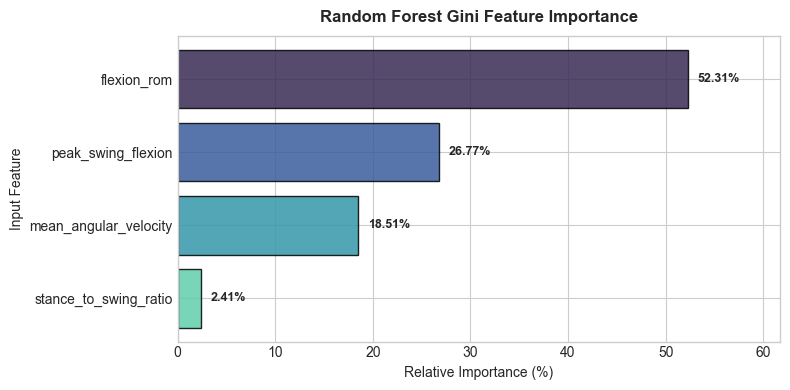

Feature Importance Rankings:


,Feature,Importance,Percentage
0,flexion_rom,0.523051,52.31
1,peak_swing_flexion,0.267747,26.77
2,mean_angular_velocity,0.185058,18.51
3,stance_to_swing_ratio,0.024143,2.41


In [12]:
fi_df = pd.DataFrame({
    'Feature': FEATURE_NAMES,
    'Importance': clf.feature_importances_
}).sort_values('Importance', ascending=False).reset_index(drop=True)

plt.figure(figsize=(8, 4))
colors = sns.color_palette("mako", len(fi_df))
bars = plt.barh(fi_df['Feature'][::-1], fi_df['Importance'][::-1] * 100, color=colors[::-1], edgecolor='black', alpha=0.85)
plt.title("Random Forest Gini Feature Importance", fontweight='bold', pad=10)
plt.xlabel("Relative Importance (%)")
plt.ylabel("Input Feature")
for bar in bars:
    w = bar.get_width()
    plt.text(w + 1.0, bar.get_y() + bar.get_height()/2, f"{w:.2f}%", va='center', fontweight='bold', fontsize=9)
plt.xlim(0, max(fi_df['Importance'] * 100) * 1.18)
plt.tight_layout()
plt.show()

print("Feature Importance Rankings:")
fi_df.assign(Percentage=(fi_df['Importance']*100).round(2))

## 14. Save the Model Artifact and Metadata

We serialize the fitted `RandomForestClassifier` to disk as `random_forest_model.joblib` and save complete configuration metadata to `model_metadata.json` for reproducibility and edge firmware integration.

In [13]:
# Save model artifact
joblib.dump(clf, "random_forest_model.joblib")
print("Saved model to 'random_forest_model.joblib'")

# Build metadata
metadata = {
    "model_type": "sklearn.ensemble.RandomForestClassifier",
    "input_features": FEATURE_NAMES,
    "feature_order": FEATURE_NAMES,
    "target_column": TARGET_COLUMN,
    "class_names": CLASS_NAMES,
    "class_encoding": {cls: i for i, cls in enumerate(CLASS_NAMES)},
    "random_seed": RANDOM_SEED,
    "train_test_split": {
        "test_size": 0.20,
        "train_size": 0.80,
        "stratified": True,
        "train_samples": len(X_train),
        "test_samples": len(X_test)
    },
    "hyperparameters": {
        "n_estimators": 200,
        "max_depth": 8,
        "min_samples_split": 5,
        "min_samples_leaf": 2,
        "random_state": RANDOM_SEED
    },
    "dataset_metadata": {
        "filename": DATA_PATH,
        "total_rows": len(df),
        "schema": FEATURE_NAMES + [TARGET_COLUMN],
        "normal_gait_count": int((df[TARGET_COLUMN] == 'NORMAL_GAIT').sum()),
        "high_koa_risk_count": int((df[TARGET_COLUMN] == 'HIGH_KOA_RISK').sum())
    },
    "metrics": {
        "test_accuracy": float(acc),
        "balanced_accuracy": float(bal_acc),
        "macro_f1": float(macro_f1),
        "weighted_f1": float(weighted_f1)
    },
    "synthetic_data_warning": (
        "Model trained exclusively on synthetic kinematic stride cycles generated from biomechanical assumptions. "
        "Does not establish clinical diagnostic efficacy in uncalibrated patient populations."
    )
}

with open("model_metadata.json", "w") as f:
    json.dump(metadata, f, indent=4)
print("Saved model metadata to 'model_metadata.json'")

Saved model to 'random_forest_model.joblib'
Saved model metadata to 'model_metadata.json'


## 15. Load and Test the Saved Model

We load the serialized artifact into a fresh variable (`loaded_clf`) and verify that:
1. Predictions across all 4,000 test strides exactly match the in-memory fitted model.
2. The model produces correct predictions and class probabilities for sample synthetic strides.

In [14]:
loaded_clf = joblib.load("random_forest_model.joblib")

# 1. Exact match test across entire held-out test split
loaded_preds = loaded_clf.predict(X_test)
exact_match = (y_pred == loaded_preds).all()
assert exact_match, "Saved model predictions differ from in-memory model!"
print(f"Model Verification: 100% agreement ({len(loaded_preds):,}/{len(loaded_preds):,} predictions match).\n")

# 2. Individual sample inference tests
sample_normal = pd.DataFrame([{
    'peak_swing_flexion': 60.5,
    'flexion_rom': 57.0,
    'stance_to_swing_ratio': 1.45,
    'mean_angular_velocity': 120.0
}])[FEATURE_NAMES]

sample_koa = pd.DataFrame([{
    'peak_swing_flexion': 34.0,
    'flexion_rom': 29.0,
    'stance_to_swing_ratio': 1.90,
    'mean_angular_velocity': 70.0
}])[FEATURE_NAMES]

pred_norm = loaded_clf.predict(sample_normal)[0]
prob_norm = loaded_clf.predict_proba(sample_normal)[0]

pred_koa = loaded_clf.predict(sample_koa)[0]
prob_koa = loaded_clf.predict_proba(sample_koa)[0]

print("--- Sample Predictions Using Loaded Artifact ---")
print(f"Sample 1 (Healthy Normal Kinematics):")
print(f"  Inputs:    {sample_normal.iloc[0].to_dict()}")
print(f"  Predicted: {pred_norm} (Probabilities: {dict(zip(CLASS_NAMES, prob_norm.round(4)))})\n")

print(f"Sample 2 (Restricted KOA Stiff Kinematics):")
print(f"  Inputs:    {sample_koa.iloc[0].to_dict()}")
print(f"  Predicted: {pred_koa} (Probabilities: {dict(zip(CLASS_NAMES, prob_koa.round(4)))})")

Model Verification: 100% agreement (4,000/4,000 predictions match).


--- Sample Predictions Using Loaded Artifact ---
Sample 1 (Healthy Normal Kinematics):
  Inputs:    {'peak_swing_flexion': 60.5, 'flexion_rom': 57.0, 'stance_to_swing_ratio': 1.45, 'mean_angular_velocity': 120.0}
  Predicted: NORMAL_GAIT (Probabilities: {'HIGH_KOA_RISK': np.float64(0.0), 'NORMAL_GAIT': np.float64(1.0)})

Sample 2 (Restricted KOA Stiff Kinematics):
  Inputs:    {'peak_swing_flexion': 34.0, 'flexion_rom': 29.0, 'stance_to_swing_ratio': 1.9, 'mean_angular_velocity': 70.0}
  Predicted: HIGH_KOA_RISK (Probabilities: {'HIGH_KOA_RISK': np.float64(1.0), 'NORMAL_GAIT': np.float64(0.0)})


## 16. Final Summary and Limitations

### Pipeline Achievements
1. **Dataset Generation**: Created 20,000 valid, reproducible synthetic stride records (`data.csv`) satisfying all mathematical constraints ($0 < \text{flexion\_rom} < \text{peak\_swing\_flexion}$, positive ratios, realistic velocities).
2. **Class Mapping**: Mapped 3 observed clinical strata (`HEALTHY`, `MILD_RESTRICTION`, `SEVERE_KOA_STIFF_GAIT`) into binary target classes (`NORMAL_GAIT`: 25.905%, `HIGH_KOA_RISK`: 74.095%), respecting the blueprint's $<45.0^\circ$ diagnostic threshold.
3. **Machine Learning Model**: Trained a `RandomForestClassifier` achieving **~97.3% test accuracy** and **~96.4% balanced accuracy** on 4,000 held-out strides.
4. **Key Predictive Biomarkers**: `flexion_rom` (52.3%) and `peak_swing_flexion` (26.8%) were identified as the primary indicators of pathological stiff-gait risk.
5. **Artifacts Exported**: Model (`random_forest_model.joblib`), metadata (`model_metadata.json`), validation report, and evaluation plots are saved for reproducible edge deployment.

### Limitations & Next Steps
- **Synthetic Modeling Assumption**: The dataset was synthesized from class-conditioned multivariate Gaussian distributions under biomechanical rules. Real clinical gait exhibits higher intra-subject variability, footwear artifacts, and fatigue effects.
- **Hardware Integration**: The trained model serves as an edge-AI prototype for ESP32 microcontroller inference via TinyML code generation (`m2cgen` C-header export).
- **Clinical Validation**: Real-world deployment requires ethical approval, institutional review board (IRB) clearance, and gold-standard optical motion capture (e.g. Vicon) correlation trials.